# Project Task 1: TP53 FASTA Analysis

In [5]:
import os
import pandas as pd
from Bio import SeqIO
from pathlib import Path

fastaloc = Path(r'TP53gene.fna')
seq_ids = []
seqs = []
lengths = []
a_counts = []
t_counts = []
g_counts = []
c_counts = []
gc_percentages = []

valid_chars = 'ATGC'

with open(fastaloc, "r") as handle:
    for record in SeqIO.parse(handle, "fasta"):
        # 1. sequence ids
        seq_ids.append(record.id)

        # sequence 
        seq = record.seq
        seqs.append(str(seq))

        # 2. sequence lengths
        lengths.append(len(seq))

        # 5. check to see if sequence only contains A, T, G, or C
        is_valid = set(seq).issubset(valid_chars)
        if is_valid:
            print(f'{record.id} has no unexpected characters.')
        else:
            print(f'{record.id} has 1 or more unexpected characters.')

        
        # 3. nucleotide composition
        a_counts.append(seq.count('A'))
        t_counts.append(seq.count('T'))
        g_counts.append(seq.count('G'))
        c_counts.append(seq.count('C'))

        # 4. calculate GC %
        gc_percentages.append( (seq.count('G') + seq.count('C')) / (seq.count('A') + seq.count('T') + seq.count('G') + seq.count('C')) * 100 )

TP53_fasta_analysis = {
    'Sequence ID': seq_ids,
    'Sequence Length': lengths,
    'A Count': a_counts,
    'T Count': t_counts,
    'G Count': g_counts,
    'C Count': c_counts,
    'GC %': gc_percentages,
    'Sequence': seqs
}

# place into easily readable dataframe
TP53fasta_df = pd.DataFrame(TP53_fasta_analysis)
display(TP53fasta_df)

TP53fasta_df.to_excel('Sequence_summary.xlsx', index=False)

NC_000017.11:c7687490-7668421 has no unexpected characters.
NC_060941.1:c7591594-7572544 has no unexpected characters.


,Sequence ID,Sequence Length,A Count,T Count,G Count,C Count,GC %,Sequence
0,NC_000017.11:c7687490-7668421,19070,4966,4688,4778,4638,49.375983,CTCAAAAGTCTAGAGCCACCGTCCAGGGAGCAGGTAGCTGCTGGGC...
1,NC_060941.1:c7591594-7572544,19051,4959,4686,4772,4634,49.372736,CTCAAAAGTCTAGAGCCACCGTCCAGGGAGCAGGTAGCTGCTGGGC...


# Project Task 2: Breast Cancer Gene Expression Analysis

In [6]:
# 1. import libraries --> pandas already imported above
import matplotlib.pyplot as plt

# 2. load CSV File --> was converted to xlsx by excel
gene_expression_df = pd.read_excel('GSE42568_series_matrix.xlsx', index_col=0)
display(gene_expression_df)

# 3. inspect data
print(gene_expression_df.shape)
print(gene_expression_df.columns), gene_expression_df.head(),gene_expression_df.info()

# 4. check data quality
print(gene_expression_df.isna().sum())
print("Duplicate rows:", gene_expression_df.duplicated().sum())

,Breast Cancer Gene Expression Analysis,Unnamed: 2,Unnamed: 3,Unnamed: 4,Unnamed: 5,Unnamed: 6,Unnamed: 7,Unnamed: 8,Unnamed: 9,Unnamed: 10,...,Unnamed: 112,Unnamed: 113,Unnamed: 114,Unnamed: 115,Unnamed: 116,Unnamed: 117,Unnamed: 118,Unnamed: 119,Unnamed: 120,Unnamed: 121
!Series_title,,,,,,,,,,,,,,,,,,,,,
!Series_geo_accession,GSE42568,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
!Series_status,Public on May 26 2013,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
!Series_submission_date,Nov 27 2012,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
!Series_last_update_date,Mar 25 2019,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
!Series_pubmed_id,23740839,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
AFFX-ThrX-M_at,7.779721,13.137754,13.120571,10.674244,8.416851,6.913481,7.757142,7.842519,6.774707,5.362483,...,11.138814,7.266111,5.704393,5.948574,7.421387,5.885597,7.092354,7.665,7.09804,6.686323
AFFX-TrpnX-3_at,2.312812,2.312812,2.312812,2.312812,2.312812,2.312812,2.312812,2.312812,2.312812,2.312812,...,2.312812,2.312812,2.312812,2.312812,2.312812,2.312812,2.312812,2.312812,2.312812,2.336713
AFFX-TrpnX-5_at,2.312812,2.560414,2.46093,2.312812,2.312812,2.312812,2.312812,2.312812,2.312812,2.312812,...,2.454202,2.312812,2.312812,2.312812,2.314241,2.312812,2.312812,2.312812,2.312812,2.312812


(54754, 121)
Index(['Breast Cancer Gene Expression Analysis', 'Unnamed: 2', 'Unnamed: 3',
       'Unnamed: 4', 'Unnamed: 5', 'Unnamed: 6', 'Unnamed: 7', 'Unnamed: 8',
       'Unnamed: 9', 'Unnamed: 10',
       ...
       'Unnamed: 112', 'Unnamed: 113', 'Unnamed: 114', 'Unnamed: 115',
       'Unnamed: 116', 'Unnamed: 117', 'Unnamed: 118', 'Unnamed: 119',
       'Unnamed: 120', 'Unnamed: 121'],
      dtype='object', length=121)
<class 'pandas.core.frame.DataFrame'>
Index: 54754 entries, !Series_geo_accession to !series_matrix_table_end
Columns: 121 entries, Breast Cancer Gene Expression Analysis to Unnamed: 121
dtypes: object(121)
memory usage: 51.0+ MB
Breast Cancer Gene Expression Analysis     3
Unnamed: 2                                38
Unnamed: 3                                38
Unnamed: 4                                38
Unnamed: 5                                38
                                          ..
Unnamed: 117                              38
Unnamed: 118             

In [7]:
# process data
sample_titles = gene_expression_df.loc['!Sample_title'].tolist()
samples = gene_expression_df.loc['!Sample_geo_accession'].tolist()
sample_types = []

for sample in sample_titles:
    if 'Normal' in sample:
        sample_types.append('Normal')
    else:
        sample_types.append('Cancerous')

# 5. Relevant genes, samples, and control groups
metadata_df = pd.DataFrame({
    'Sample': samples,
    'Sample Title': sample_titles,
    'Condition': sample_types
})
metadata_df = metadata_df.set_index('Sample')
display(metadata_df)

expression_data = gene_expression_df.iloc[77:].T.reset_index(drop=True)
expression_data.drop(columns=['!series_matrix_table_end'], inplace=True)
display(expression_data)

,Sample Title,Condition
Sample,,
GSM1045191,"Normal breast, N1_15_12_04",Normal
GSM1045192,"Normal breast, N4_14_12_04",Normal
GSM1045193,"Normal breast, N5_15_12_04",Normal
GSM1045194,"Normal breast, N6_14_12_04",Normal
GSM1045195,"Normal breast, P1_15_12_04",Normal
...,...,...
GSM1045307,"Breast cancer, T94_9_12_04",Cancerous
GSM1045308,"Breast cancer, T97_3_12_04",Cancerous
GSM1045309,"Breast cancer, T98_22_12_04",Cancerous


!Series_title,ID_REF,1007_s_at,1053_at,117_at,121_at,1255_g_at,1294_at,1316_at,1320_at,1405_i_at,...,AFFX-r2-Ec-bioD-3_at,AFFX-r2-Ec-bioD-5_at,AFFX-r2-P1-cre-3_at,AFFX-r2-P1-cre-5_at,AFFX-ThrX-3_at,AFFX-ThrX-5_at,AFFX-ThrX-M_at,AFFX-TrpnX-3_at,AFFX-TrpnX-5_at,AFFX-TrpnX-M_at
0,GSM1045191,5.640239,5.074866,4.19177,3.574706,2.312812,5.474018,7.392011,2.545487,6.363695,...,13.900585,13.491092,14.891877,14.749976,10.053204,5.152432,7.779721,2.312812,2.312812,2.312812
1,GSM1045192,3.557696,4.984593,4.269061,4.065623,2.409371,5.246784,6.06138,2.312812,6.886877,...,14.694493,14.482319,15.17701,15.107731,14.600338,10.40143,13.137754,2.312812,2.560414,2.312812
2,GSM1045193,3.132007,5.109481,4.131843,3.574706,2.312812,6.460169,5.862504,2.312812,4.953922,...,14.528211,14.321748,15.195278,15.129354,14.114741,10.4099,13.120571,2.312812,2.46093,2.312812
3,GSM1045194,6.865108,5.473609,3.616546,3.574706,2.312812,5.146087,5.954431,2.312812,5.04488,...,14.891396,14.796693,15.357952,15.3601,12.69652,7.505545,10.674244,2.312812,2.312812,2.312812
4,GSM1045195,4.955184,5.3484,4.296657,3.799293,2.34963,5.823408,7.679896,2.342446,5.468036,...,14.307755,13.950866,15.133403,15.021234,10.747295,5.964108,8.416851,2.312812,2.312812,2.312812
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
116,GSM1045307,7.168925,5.358832,4.131843,3.50241,2.312812,6.098925,6.084313,2.312812,7.71141,...,13.984397,13.605246,14.950453,14.738329,8.56263,3.697247,5.885597,2.312812,2.312812,2.312812
117,GSM1045308,7.935322,4.804079,3.967933,3.574706,2.312812,5.103976,5.881213,2.312812,4.599493,...,13.896354,13.561228,14.921628,14.80634,9.812059,3.966759,7.092354,2.312812,2.312812,2.312812
118,GSM1045309,6.937005,5.488895,4.392234,3.579242,2.312812,6.371564,5.612191,2.312812,3.817553,...,13.947824,13.55796,14.823999,14.727446,10.160657,3.551799,7.665,2.312812,2.312812,2.312812
119,GSM1045310,8.822155,5.575357,4.269244,3.574706,2.312812,5.782536,6.164751,2.312812,4.061651,...,12.94902,12.439237,14.164533,13.948848,9.60809,3.828618,7.09804,2.312812,2.312812,2.312812


In [8]:
# separate control and experimental group datas
control_idx = []
cancer_idx = []

for idx, row in expression_data.iterrows():
    if metadata_df.loc[row['ID_REF'],'Condition'] == 'Normal':
        control_idx.append(idx)
    else:
        cancer_idx.append(idx)

control_df = expression_data.iloc[control_idx]
cancer_df = expression_data.iloc[cancer_idx]

display(control_df)
display(cancer_df)

!Series_title,ID_REF,1007_s_at,1053_at,117_at,121_at,1255_g_at,1294_at,1316_at,1320_at,1405_i_at,...,AFFX-r2-Ec-bioD-3_at,AFFX-r2-Ec-bioD-5_at,AFFX-r2-P1-cre-3_at,AFFX-r2-P1-cre-5_at,AFFX-ThrX-3_at,AFFX-ThrX-5_at,AFFX-ThrX-M_at,AFFX-TrpnX-3_at,AFFX-TrpnX-5_at,AFFX-TrpnX-M_at
0,GSM1045191,5.640239,5.074866,4.19177,3.574706,2.312812,5.474018,7.392011,2.545487,6.363695,...,13.900585,13.491092,14.891877,14.749976,10.053204,5.152432,7.779721,2.312812,2.312812,2.312812
1,GSM1045192,3.557696,4.984593,4.269061,4.065623,2.409371,5.246784,6.06138,2.312812,6.886877,...,14.694493,14.482319,15.17701,15.107731,14.600338,10.40143,13.137754,2.312812,2.560414,2.312812
2,GSM1045193,3.132007,5.109481,4.131843,3.574706,2.312812,6.460169,5.862504,2.312812,4.953922,...,14.528211,14.321748,15.195278,15.129354,14.114741,10.4099,13.120571,2.312812,2.46093,2.312812
3,GSM1045194,6.865108,5.473609,3.616546,3.574706,2.312812,5.146087,5.954431,2.312812,5.04488,...,14.891396,14.796693,15.357952,15.3601,12.69652,7.505545,10.674244,2.312812,2.312812,2.312812
4,GSM1045195,4.955184,5.3484,4.296657,3.799293,2.34963,5.823408,7.679896,2.342446,5.468036,...,14.307755,13.950866,15.133403,15.021234,10.747295,5.964108,8.416851,2.312812,2.312812,2.312812
5,GSM1045196,5.573674,5.572707,4.184048,3.803312,2.312812,5.647246,7.1294,2.678847,6.226193,...,12.907362,12.294574,14.345538,13.988833,9.29171,4.276242,6.913481,2.312812,2.312812,2.312812
6,GSM1045197,4.7141,5.675239,4.000772,3.643243,2.312812,4.932572,6.024533,2.974022,6.3589,...,13.206247,12.641079,14.328896,14.174311,10.046509,4.139236,7.757142,2.312812,2.312812,2.317725
7,GSM1045198,5.234298,5.792026,4.984939,4.053245,2.312812,5.858247,7.264851,2.312812,7.133675,...,13.71772,13.18707,14.735959,14.589189,10.195406,4.807221,7.842519,2.312812,2.312812,2.312812
8,GSM1045199,5.050853,6.185706,4.958126,3.574706,2.312812,5.830461,6.400669,2.584058,4.692151,...,13.064803,12.488609,14.36403,13.989012,9.154748,3.680959,6.774707,2.312812,2.312812,2.312812
9,GSM1045200,6.913114,5.230088,3.554531,3.580369,2.312812,6.426124,7.296081,2.312812,7.254283,...,12.538189,11.879384,13.715162,13.445611,9.132125,3.169073,5.362483,2.312812,2.312812,2.312812


!Series_title,ID_REF,1007_s_at,1053_at,117_at,121_at,1255_g_at,1294_at,1316_at,1320_at,1405_i_at,...,AFFX-r2-Ec-bioD-3_at,AFFX-r2-Ec-bioD-5_at,AFFX-r2-P1-cre-3_at,AFFX-r2-P1-cre-5_at,AFFX-ThrX-3_at,AFFX-ThrX-5_at,AFFX-ThrX-M_at,AFFX-TrpnX-3_at,AFFX-TrpnX-5_at,AFFX-TrpnX-M_at
17,GSM1045208,7.996061,5.311982,4.041873,3.574706,2.312812,6.261753,6.231768,2.312812,6.30234,...,13.591463,13.268729,14.496146,14.369979,10.339351,4.106648,7.798765,2.312812,2.312812,2.312812
18,GSM1045209,8.389665,5.588622,4.369333,3.574706,2.312812,5.311189,7.198395,2.312812,5.572859,...,14.371413,13.958767,15.036319,14.877701,12.48795,7.555068,10.496528,2.312812,2.312812,2.312812
19,GSM1045210,7.883103,5.503518,3.945863,3.574706,2.312812,6.519589,7.018177,2.312812,6.934153,...,14.506124,14.251371,15.229213,15.146143,10.253852,4.263207,7.39987,2.312812,2.312812,2.312812
20,GSM1045211,6.394748,4.900223,4.131843,3.574706,2.312812,4.823558,7.214731,2.312812,5.915115,...,14.655426,14.384024,15.331037,15.175541,12.219683,6.858442,9.76254,2.312812,2.312812,2.312812
21,GSM1045212,7.46092,7.203254,6.046027,3.574706,2.312812,6.300663,5.050737,2.312812,9.360997,...,11.813053,11.359787,13.089595,12.925096,7.78024,3.112584,5.482683,2.312812,2.312812,2.312812
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
116,GSM1045307,7.168925,5.358832,4.131843,3.50241,2.312812,6.098925,6.084313,2.312812,7.71141,...,13.984397,13.605246,14.950453,14.738329,8.56263,3.697247,5.885597,2.312812,2.312812,2.312812
117,GSM1045308,7.935322,4.804079,3.967933,3.574706,2.312812,5.103976,5.881213,2.312812,4.599493,...,13.896354,13.561228,14.921628,14.80634,9.812059,3.966759,7.092354,2.312812,2.312812,2.312812
118,GSM1045309,6.937005,5.488895,4.392234,3.579242,2.312812,6.371564,5.612191,2.312812,3.817553,...,13.947824,13.55796,14.823999,14.727446,10.160657,3.551799,7.665,2.312812,2.312812,2.312812
119,GSM1045310,8.822155,5.575357,4.269244,3.574706,2.312812,5.782536,6.164751,2.312812,4.061651,...,12.94902,12.439237,14.164533,13.948848,9.60809,3.828618,7.09804,2.312812,2.312812,2.312812


In [15]:
# 5. find averages for each probe --> keep control and cancerous averages separate
import numpy as np

control_probe_averages = []
cancer_probe_averages = []
probes_list = control_df.columns.tolist()[1:]

for probe in probes_list:
    control_probe_averages.append(control_df[probe].mean())
    cancer_probe_averages.append(cancer_df[probe].mean())

probe_averages = pd.DataFrame({
    'Affymetrix Probe': probes_list,
    'Normal': control_probe_averages,
    'Cancerous': cancer_probe_averages
})
display(probe_averages)
# probe_averages.to_excel('Gene_expression_summary.xlsx', index=False)

# 5. find median expression for each sample
control_medians = []
cancer_medians = []
control_samples = control_df['ID_REF'].tolist()
cancer_samples = cancer_df['ID_REF'].tolist()

for _,row in control_df.iterrows():
    control_medians.append(row.iloc[1:].median())

for _,row in cancer_df.iterrows():
    cancer_medians.append(row.iloc[1:].median())

normal_medians_df = pd.DataFrame({
    'Normal Sample ID': control_samples,
    'Median Expression Value': control_medians
})

cancer_medians_df = pd.DataFrame({
    'Cancerous Sample ID': cancer_samples,
    'Median Expression Value': cancer_medians
})
display(normal_medians_df)
display(cancer_medians_df)
all_sample_medians = pd.concat([normal_medians_df, cancer_medians_df], ignore_index=True)

probe_averages.loc[len(probe_averages)] = np.nan

gene_ex_summary = pd.concat([probe_averages, all_sample_medians], ignore_index=True)
gene_ex_summary.to_excel('Gene_expression_summary.xlsx', index=False)

,Affymetrix Probe,Normal,Cancerous
0,1007_s_at,5.143417,7.521487
1,1053_at,5.491319,5.686114
2,117_at,4.215687,4.478162
3,121_at,3.721981,3.669668
4,1255_g_at,2.320657,2.315915
...,...,...,...
54670,AFFX-ThrX-5_at,5.578909,4.439078
54671,AFFX-ThrX-M_at,8.434227,7.420149
54672,AFFX-TrpnX-3_at,2.312812,2.313736
54673,AFFX-TrpnX-5_at,2.336089,2.316446


,Normal Sample ID,Median Expression Value
0,GSM1045191,2.790573
1,GSM1045192,3.110262
2,GSM1045193,3.178932
3,GSM1045194,3.105461
4,GSM1045195,2.768904
5,GSM1045196,2.765418
6,GSM1045197,2.780233
7,GSM1045198,2.776031
8,GSM1045199,2.753986
9,GSM1045200,2.815899


,Cancerous Sample ID,Median Expression Value
0,GSM1045208,2.795348
1,GSM1045209,2.854757
2,GSM1045210,2.858913
3,GSM1045211,3.044570
4,GSM1045212,2.762917
...,...,...
99,GSM1045307,2.782812
100,GSM1045308,2.766579
101,GSM1045309,2.881316
102,GSM1045310,2.726207


# Project Task 3: Visualization

/var/folders/3r/x_yfn5cj0n1b3r2g20_phb800000gn/T/ipykernel_2330/104570509.py:22: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  plt.tight_layout()
/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/IPython/core/pylabtools.py:170: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  fig.canvas.print_figure(bytes_io, **kw)


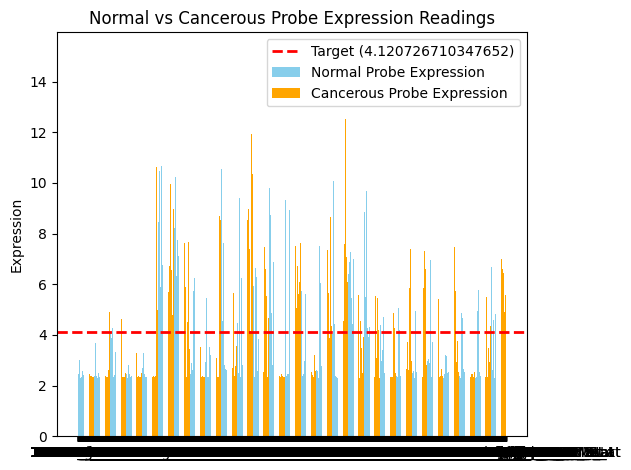

In [28]:
#  Plot 1 - Bar Chart
all_gene_avgs = probe_averages['Normal'].tolist()
all_gene_avgs = all_gene_avgs + probe_averages['Cancerous'].tolist()
avg_gene_ex = np.mean(all_gene_avgs)

x = np.arange(len(probes_list)) 
width = 0.35 

fig, ax = plt.subplots()

rects1 = ax.bar(x - width/2, control_probe_averages, width, label='Normal Probe Expression', color='skyblue')
rects2 = ax.bar(x + width/2, cancer_probe_averages, width, label='Cancerous Probe Expression', color='orange')

plt.axhline(y=avg_gene_ex, color='red', linestyle='--', linewidth=2, label=f'Target ({avg_gene_ex})')

ax.set_ylabel('Expression')
ax.set_title('Normal vs Cancerous Probe Expression Readings')
ax.set_xticks(x)
ax.set_xticklabels(probes_list)
ax.legend()

plt.tight_layout()
plt.show()

0.4050843480414934


,Low Cancer Expression Probe ID,Normal Expression,Cancerous Expression
0,1552309_a_at,5.806621,3.772645
1,1552365_at,4.951833,3.814119
2,1552509_a_at,7.415681,2.855393
3,1552519_at,8.453281,2.623145
4,1552616_a_at,5.675240,2.426236
...,...,...,...
941,45288_at,5.591740,3.719512
942,53991_at,5.048258,3.249078
943,65718_at,5.560296,3.867276
944,89977_at,6.868362,2.502708


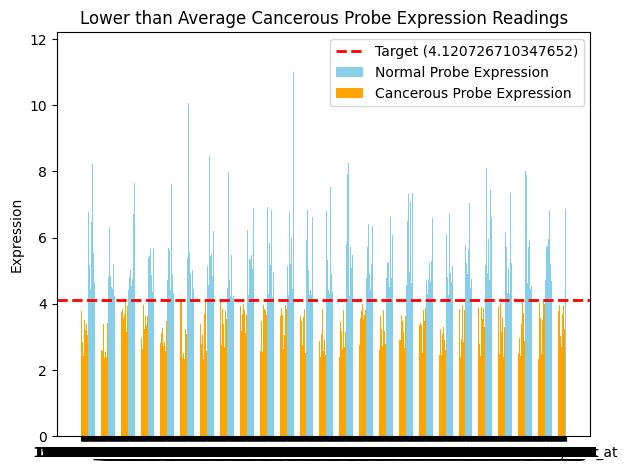

,High Cancer Expression Probe ID,Normal Expression,Cancerous Expression
0,1552477_a_at,3.105721,5.106791
1,1552482_at,3.895487,5.252157
2,1552632_a_at,3.298487,4.295937
3,1552689_at,3.695847,4.515052
4,1552719_at,3.545851,4.642633
...,...,...,...
1315,59697_at,2.661644,4.340283
1316,60815_at,4.117489,6.364211
1317,65438_at,3.854710,5.082591
1318,65517_at,3.458273,7.007064


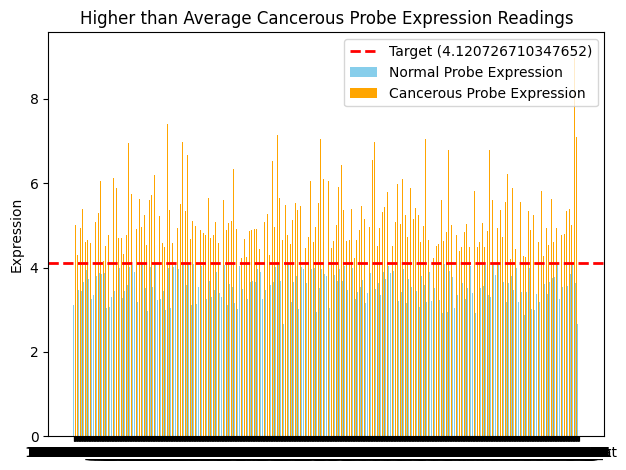

In [30]:
probe_averages = probe_averages[:-1]
differences = []
for _,row in probe_averages.iterrows(): 
    differences.append(abs(row['Normal'] - row['Cancerous']))

delta = np.mean(differences)
print(delta)

# low cancer expression
low_cancer_probes = []
high_normal = []
low_cancer = []

# high cancer expression
high_cancer_probes = []
low_normal = []
high_cancer = []

for _,row in probe_averages.iterrows():
    if abs(row['Normal'] - row['Cancerous']) > 2*delta:
        if (row['Normal'] > avg_gene_ex) and (row['Cancerous'] <= avg_gene_ex):
            low_cancer_probes.append(row['Affymetrix Probe'])
            high_normal.append(row['Normal'])
            low_cancer.append(row['Cancerous'])
        elif (row['Normal'] <= avg_gene_ex) and (row['Cancerous'] > avg_gene_ex):
            high_cancer_probes.append(row['Affymetrix Probe'])
            low_normal.append(row['Normal'])
            high_cancer.append(row['Cancerous'])

low_cancer_ex = pd.DataFrame({
    'Low Cancer Expression Probe ID': low_cancer_probes,
    'Normal Expression': high_normal,
    'Cancerous Expression': low_cancer
})

high_cancer_ex = pd.DataFrame({
    'High Cancer Expression Probe ID': high_cancer_probes,
    'Normal Expression': low_normal,
    'Cancerous Expression': high_cancer
})

# display low cancer
display(low_cancer_ex)

x = np.arange(len(low_cancer_probes)) 
width = 0.35 

fig, ax = plt.subplots()

rects1 = ax.bar(x - width/2, high_normal, width, label='Normal Probe Expression', color='skyblue')
rects2 = ax.bar(x + width/2, low_cancer, width, label='Cancerous Probe Expression', color='orange')

plt.axhline(y=avg_gene_ex, color='red', linestyle='--', linewidth=2, label=f'Target ({avg_gene_ex})')

ax.set_ylabel('Expression')
ax.set_title('Lower than Average Cancerous Probe Expression Readings')
ax.set_xticks(x)
ax.set_xticklabels(low_cancer_probes)
ax.legend()

plt.tight_layout()
plt.savefig("Low_cancer_expression.png", dpi=300, bbox_inches="tight")
plt.show()

# display high cancer
display(high_cancer_ex)

x = np.arange(len(high_cancer_probes)) 
width = 0.35 

fig, ax = plt.subplots()

rects1 = ax.bar(x - width/2, low_normal, width, label='Normal Probe Expression', color='skyblue')
rects2 = ax.bar(x + width/2, high_cancer, width, label='Cancerous Probe Expression', color='orange')

plt.axhline(y=avg_gene_ex, color='red', linestyle='--', linewidth=2, label=f'Target ({avg_gene_ex})')

ax.set_ylabel('Expression')
ax.set_title('Higher than Average Cancerous Probe Expression Readings')
ax.set_xticks(x)
ax.set_xticklabels(high_cancer_probes)
ax.legend()

plt.tight_layout()
plt.savefig("High_cancer_expression.png", dpi=300, bbox_inches="tight")
plt.show()

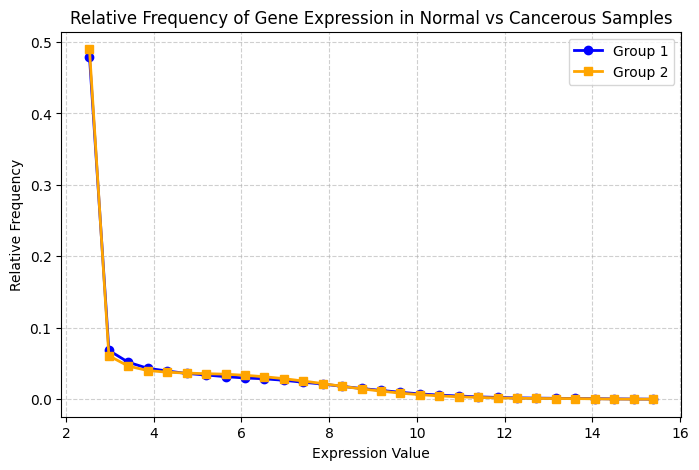

In [31]:
# Plot 2 - Histogram

all_normal_readings = []
all_cancer_readings = []

for _,row in control_df.iterrows():
    all_normal_readings = all_normal_readings + row[1:].tolist()

for _,row in cancer_df.iterrows():
    all_cancer_readings = all_cancer_readings + row[1:].tolist()

# 3. Calculate relative frequencies
count1, edges1 = np.histogram(all_normal_readings, bins=30)
rel_freq1 = count1 / len(all_normal_readings)

count2, edges2 = np.histogram(all_cancer_readings, bins=30)
rel_freq2 = count2 / len(all_cancer_readings)

# 4. Find bin midpoints for x-axis
bin_centers = 0.5 * (edges1[:-1] + edges1[1:])

# 5. Plot lines instead of bars
plt.figure(figsize=(8, 5))
plt.plot(
    bin_centers, 
    rel_freq1, 
    marker='o', 
    label='Group 1', 
    linewidth=2, 
    color='blue'
)
plt.plot(
    bin_centers,
    rel_freq2,
    marker='s',
    label='Group 2',
    linewidth=2,
    color='orange',
)

plt.xlabel('Expression Value')
plt.ylabel('Relative Frequency')
plt.title('Relative Frequency of Gene Expression in Normal vs Cancerous Samples')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.6)

plt.savefig("Relative_frequency_of_NormalvsCancerous.png", dpi=300, bbox_inches="tight")
plt.show()


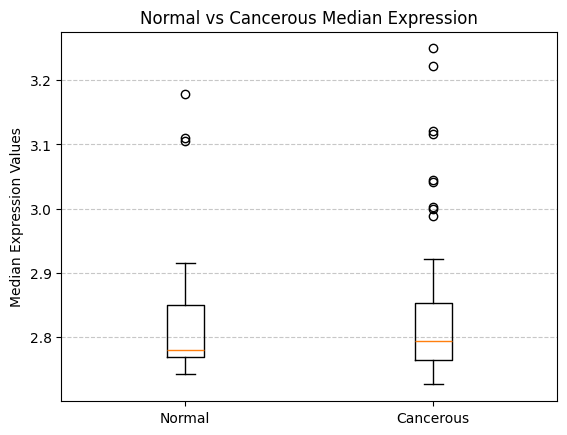

In [32]:
# Plot 3 - Box Plot
median_data = [control_medians, cancer_medians]

# 3. Create the box plot and specify group labels
plt.boxplot(median_data, tick_labels=['Normal', 'Cancerous'])

# 4. Add optional labels and show the plot
plt.title('Normal vs Cancerous Median Expression')
plt.ylabel('Median Expression Values')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.savefig("Box_plot_of_median_expression_values", dpi=300, bbox_inches="tight")
plt.show()